# Homework 1. Свежие вопросы и агент на них отвечает

In [ ]:
%pip install -r requirements.txt

In [1]:
import os, re, sys, json, time, ast, operator, subprocess
from pathlib import Path
from dataclasses import dataclass, field
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field, ValidationError

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
assert os.getenv("OPENROUTER_API_KEY"), "нет ключа: положите его в .env рядом с ноутбуком или в Kaggle Secrets"

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}",
           "HTTP-Referer": "https://postypashki.ru", "X-Title": "agents-course-seminar01"}
MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5", "strong": "anthropic/claude-sonnet-4.6"}
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = Path("data")
TRACES = Path("traces")
TRACES.mkdir(exist_ok=True)
IMG = Path("img")
IMG.mkdir(exist_ok=True)

In [2]:
@dataclass
class Ledger:
    calls: list = field(default_factory=list)

    def add(self, tag, model, usage, seconds=0.0):
        p, c = usage.get("prompt_tokens", 0), usage.get("completion_tokens", 0)
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": p, "completion": c,
                           "cost": cost, "seconds": round(seconds, 2)})
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    def table(self):
        df = pd.DataFrame(self.calls)
        return df.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                completion=("completion", "sum"), cost=("cost", "sum"),
                                                seconds=("seconds", "sum")).round(5)

ledger = Ledger()

In [3]:
def post_with_retry(body, attempts=3):
    for attempt in range(attempts):
        r = requests.post(CHAT_URL, json=body, headers=HEADERS, timeout=120)
        if r.status_code == 200:
            return r.json()
        if r.status_code in (429, 500, 502, 503) and attempt < attempts - 1:
            time.sleep(1.5 * (attempt+1))
            continue
        raise RuntimeError(f"HTTP [{r.status_code}]: {r.text[:5000]}")

In [4]:
def chat(messages, model, tools=None, tag="chat", temperature=None, max_tokens=None):
    body = {"model": model, "messages": messages, "usage": {"include": True}}
    if tools:
        body["tools"] = tools
        body["tool_choice"] = "auto"
    if temperature:
        body["temperature"] = temperature
    if max_tokens:
        body["max_tokens"] = max_tokens
    started = time.perf_counter()
    data = post_with_retry(body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]

In [5]:
def cost_time_chart(tag):
    df = pd.DataFrame([c for c in ledger.calls if c["tag"] == tag])
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.scatter(df["cost"] * 100, df["seconds"], s=140, color=COLORS["violet"])
    for _, r in df.iterrows():
        ax.annotate(r["model"], (r["cost"] * 100, r["seconds"]), xytext=(8, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("цена ответа, центы (логарифмическая шкала)")
    ax.set_ylabel("время ответа, секунды")
    ax.grid(alpha=0.3)
    return fig

In [6]:
class Answer(BaseModel):
    reasoning: str = Field(description="ход решения в два-три предложения")
    final: str = Field(description="только итоговый ответ: число или короткая фраза")

SCHEMA_PROMPT = "Отвечай строго одним JSON-объектом по этой схеме, без текста вокруг, строки в одну линию, без лишних отступов, \t, \n:\n{schema}"

def json_from(text):
    m = re.search(r"\{.*\}", text or "", re.S)
    if not m:
        raise ValueError("в ответе нет JSON")
    return json.loads(m.group(0), strict=False)

In [7]:
def ask_structured(question, model, schema=Answer, attempts=3):
    messages = [
        {"role": "system", "content": SCHEMA_PROMPT.format(schema=json.dumps(schema.model_json_schema(), ensure_ascii=False))},
        {"role": "user", "content": question}
    ]
    for _ in range(attempts):
        msg = chat(messages, model, tag="struct")
        try:
            return schema.model_validate(json_from(msg["content"]))
        except (ValidationError, ValueError) as e:
            messages += [msg, {"role": "user", "content": f"Ответ не прошел проверку на структуру: {e}. Верни ответ по строгой JSON схеме"}]
    raise ValueError("Модель не справилась")

In [8]:
def normalize(text):
    text = re.sub(r"[^\w\s]", " ", str(text).lower().replace(",", ""))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())

def is_correct(task, answer):
    if not answer or not task.get("answer"):
        return False
    if task["source"] == "gsm8k":
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(answer).replace(",", ""))
        return bool(nums) and abs(float(nums[-1]) - float(task["answer"])) < 1e-6
    return normalize(task["answer"]) in normalize(answer)

def summary(config, model, n, correct, cost, steps, seconds=0.0):
    accuracy = correct / n if n > 0 else 0.0
    cost_per_task = cost / n if n > 0 else 0.0
    cost_per_correct = cost / correct if correct > 0 else float("inf")
    return {
        "config": config,
        "model": model.split("/")[-1],
        "n": n,
        "accuracy": round(accuracy, 4),
        "cost_per_task": round(cost_per_task, 5),
        "cost_per_correct": round(cost_per_correct, 5),
        "avg_steps": round(steps, 2),
        "avg_seconds": round(seconds, 1)}

def compare_models(tasks, models):
    rows = []
    for name, model in models.items():
        before, correct, started = ledger.total, 0, time.perf_counter()
        for task in tasks:
            try:
                correct += is_correct(task, ask_structured(task["question"], model).final)
            except Exception:
                pass
        rows.append(summary("без инструментов, JSON", model, len(tasks), correct, ledger.total - before, 1,
                            (time.perf_counter() - started) / len(tasks)))
    return pd.DataFrame(rows)

def compare_chart(df):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
    axes[0].bar(df["model"], df["accuracy"] * 100, color=COLORS["violet"])
    axes[0].set_ylabel("доля верных, %")
    axes[0].set_ylim(0, 105)
    axes[1].bar(df["model"], df["cost_per_correct"] * 100, color=COLORS["amber"])
    axes[1].set_ylabel("цена верного ответа, центы")
    axes[2].bar(df["model"], df["avg_seconds"], color=COLORS["teal"])
    axes[2].set_ylabel("секунд на задачу")
    for ax in axes:
        ax.tick_params(axis="x", labelrotation=12)
        ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    return fig

### Цикл ReAct

In [9]:
TOOLS = {}

def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}

OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv,
       ast.Pow: operator.pow, ast.USub: operator.neg, ast.Mod: operator.mod}

def evaluate(node):
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in OPS:
        return OPS[type(node.op)](evaluate(node.left), evaluate(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in OPS:
        return OPS[type(node.op)](evaluate(node.operand))
    raise ValueError("допустимы только числа и арифметика")

class CalcArgs(BaseModel):
    expr: str = Field(description="арифметическое выражение, например 17*23+5")

def calculator(expr: str) -> str:
    try:
        val = evaluate(ast.parse(expr.replace(",", "."), mode="eval").body)
        return str(int(val)) if float(val).is_integer() else f"{val:.4f}".rstrip("0")
    except Exception as e:
        return f"ошибка вычисления: {e}"

register(calculator, CalcArgs, "Считает арифметическое выражение: числа, скобки, + - * / ** %")
json.dumps(TOOLS["calculator"]["schema"], ensure_ascii=False, indent=1)

'{\n "type": "function",\n "function": {\n  "name": "calculator",\n  "description": "Считает арифметическое выражение: числа, скобки, + - * / ** %",\n  "parameters": {\n   "properties": {\n    "expr": {\n     "description": "арифметическое выражение, например 17*23+5",\n     "title": "Expr",\n     "type": "string"\n    }\n   },\n   "required": [\n    "expr"\n   ],\n   "title": "CalcArgs",\n   "type": "object"\n  }\n }\n}'

In [10]:
SYSTEM = (
    "Ты отвечаешь на вопросы о событиях 2026 года. Никогда не отвечай по памяти — только через инструменты. "
    "Стратегия: "
    "1. Вызови web_search, чтобы найти нужную статью. Он возвращает вступление и список других статей. "
    "2. Если во вступлении нет нужного факта (даты, имени, числа), ищи в результатах обзорные статьи "
    "типа '2026 in spaceflight', '2026 in science', '2026 in climate change'. "
    "3. Вызови page_find с названием обзорной статьи и ключевыми словами из вопроса, чтобы прочитать "
    "полный текст и найти нужный факт. "
    "4. Не делай одинаковых вызовов с похожими аргументами. "
    "Когда ответ готов, напиши его последней строкой в формате FINAL: <короткий ответ>. "
    "Для числовых ответов пиши только число, для фактов — короткую фразу до 10 слов."
)

@dataclass
class Run:
    question: str
    answer: str
    steps: int
    messages: list
    cost: float = 0.0
    seconds: float = 0.0

def looped(seen, calls):
    keys = [(c["function"]["name"], c["function"]["arguments"]) for c in calls]
    repeated = any(k in seen for k in keys)
    seen.update(keys)
    return repeated

def finish(model, messages, step):
    del messages[-1]
    messages.append({"role": "user", "content": "Инструменты больше недоступны. Ответь по тому, что уже известно, последней строкой FINAL: <ответ>."})
    msg = chat(messages, model, tag="agent", max_tokens=1000)
    messages.append(msg)
    return msg.get("content") or "", step + 1

In [11]:
def run_tool(call):
    name = call["function"]["name"]

    try:
        spec = TOOLS[name]
        args = spec["args"].model_validate_json(call["function"]["arguments"])
        result = spec["fn"](**args.model_dump())
    except Exception as e:
        result = f"НЕ удалось вызвать инструмент {name}: {e}"
    return {"role": "tool", "tool_call_id" : call["id"], "content": str(result)[:2000]}


In [12]:
def agent_loop(messages, model, tool_names, max_steps):
    seen = set()
    for step in range(1, max_steps + 1):
        msg = chat(messages, model, tools=[TOOLS[n]["schema"] for n in tool_names] or None, tag='agent', max_tokens=2000)
        messages.append(msg)
        calls = msg.get("tool_calls") or []

        if not calls:
            return msg.get("content") or "", step
        if looped(seen, calls) or step == max_steps:
            return finish(model, messages, step)

        messages += [run_tool(c) for c in calls]


In [13]:
def agent(question, model, tool_names, max_steps=8):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    before, started = ledger.total, time.perf_counter()
    answer, steps = agent_loop(messages, model, tool_names, max_steps)
    return Run(question, answer, steps, messages, ledger.total - before, time.perf_counter() - started)

def show_trace(run):
    for m in run.messages[1:]:
        calls = "; ".join(f"{c['function']['name']}{c['function']['arguments']}" for c in m.get("tool_calls") or [])
        text = " ".join((m.get("content") or "").split())[:180]
        print(f"{m['role']:9s}| {text} {calls}")
    print(f"шагов: {run.steps}, цена: {run.cost * 100:.3f} ¢, время: {run.seconds:.1f} c")

## Инструменты

In [14]:
WIKI = "https://en.wikipedia.org/w/api.php"
WIKI_HEADERS = {"User-Agent": "agents-course-seminar01/1.0 (https://postypashki.ru; educational project)"}

def wiki(params, attempts=3):
    for attempt in range(attempts):
        r = requests.get(WIKI, params={**params, "format": "json"}, headers=WIKI_HEADERS, timeout=15)
        if r.status_code == 200 and r.headers.get("content-type", "").startswith("application/json"):
            return r.json()["query"]
        time.sleep(1.0 + attempt)
    raise RuntimeError(f"Википедия ответила {r.status_code}")

class SearchArgs(BaseModel):
    query: str = Field(description="короткий поисковый запрос: имя, название, термин")

class ExecArgs(BaseModel):
    code: str = Field(description="код на Python; результат надо напечатать через print")

In [15]:
def web_search(query: str) -> str:
    hits = wiki({"action": "query", "list": "search", "srsearch": query, "srlimit": 3})["search"]

    if not hits:
        return "No data"
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "exintro": 1, "titles": hits[0]["title"]})["pages"]
    text = " ".join(next(iter(pages.values())).get("extract", "").split())
    others = ", ".join(h["title"] for h in hits[1:])
    return f"[{hits[0]['title']}] {text[:5000]}" + (f" | other articles: {others}" if others else "")

In [16]:
def python_exec(code: str) -> str:
    try:
        r = subprocess.run([sys.executable, "-I", "-c", code], capture_output=True, text=True, timeout=5)
    except subprocess.TimeoutExpired:
        return "Код превысил 5 сек"
    out = (r.stdout + r.stderr).strip()
    return out[:5000] if out else "Код исполнился но результат пустой"


In [17]:
class PageFindArgs(BaseModel):
    title: str = Field(description="точное название статьи в Википедии, например 'Python (programming language)'")
    keywords: str = Field(description="от 2 до 5 ключевых слов через пробел, взятых из вопроса")

def page_find(title: str, keywords: str) -> str:
    try:
        pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "titles": title, "redirects": 1})["pages"]
    except Exception as e:
        return f"ошибка поиска страницы: {e}"

    page = next(iter(pages.values()))
    if "missing" in page:
        return f"страница '{title}' не найдена"
    text = page.get("extract", "")
    if not text:
        return f"страница '{title}' пустая"

    # print("[TEXT]: ", text[:2000])
    words = [w for w in re.findall(r"\w+", keywords.lower()) if len(w) > 2]
    if not words:
        return "нет ключевых слов для поиска"

    lines = [l.strip() for l in text.splitlines() if l.strip()]
    threshold = max(1, (len(words) + 1) // 2)
    hits = [l for l in lines if sum(w in l.lower() for w in words) >= threshold]

    if not hits:
        return f"ключевые слова '{keywords}' не найдены в статье '{title}'"

    return "\n".join(h[:400] for h in hits[:6])

In [19]:
register(web_search, SearchArgs, "Ищет статью в англоязычной Википедии и возвращает её вступление")
register(python_exec, ExecArgs, "Выполняет код на Python в отдельном процессе и возвращает то, что он напечатал")
register(page_find, PageFindArgs, "Ищет ключевые слова в статье Википедии и возвращает строки, где они встречаются")

assert calculator("2+2") == "4"
assert calculator("2**10") == "1024"
assert "ошибка" in calculator("__import__('os')")
assert web_search("Scott Derrickson").startswith("[Scott Derrickson]")
assert web_search("qwxzv 1234567 nonsense") == "No data"
assert python_exec("print(sum(range(10)))") == "45"
assert "ZeroDivisionError" in python_exec("1/0")
assert "Код превысил 5 сек" in python_exec("import time; time.sleep(10)")
result = page_find("2026 in science", "Artemis moon NASA")
assert isinstance(result, str)
assert "artemis" in result or "moon" in result or "flyby" in result
assert "ключевые слова 'qwxzv nonsense xyz123' не найдены" in page_find("2026 in science", "qwxzv nonsense xyz123")
assert "не найдена" in page_find("This article does not exist at all 99999", "bla bla bla")
"инструменты работают"

'инструменты работают'

In [20]:
for q in ["Ed Wood", "Ed Wood film", "Kiss and Tell 1945 film"]:
    print(q, "->", web_search(q)[:220], "\n")

Ed Wood -> [Ed Wood] Edward Davis Wood Jr. (October 10, 1924 – December 10, 1978) was an American filmmaker, actor and novelist. In the 1950s, Wood directed several low-budget science fiction, crime and horror films that later beca 

Ed Wood film -> [Ed Wood (film)] Ed Wood is a 1994 American biographical film directed and produced by Tim Burton and starring Johnny Depp as the eponymous cult filmmaker. The film concerns the period in Wood's life when he made his bes 

Kiss and Tell 1945 film -> [Kiss and Tell (1945 film)] Kiss and Tell is a 1945 American comedy film starring then 17-year-old Shirley Temple as Corliss Archer. In the film, two teenage girls cause their respective parents much concern when they st 



In [22]:
run = agent("Сколько дней осталось до нового года? Посчитай кодом по сегодняшней дате.", MODELS["cheap"], ["python_exec"])
show_trace(run)

user     | Сколько дней осталось до нового года? Посчитай кодом по сегодняшней дате. 
assistant|  python_exec{"code":"from datetime import datetime\n\n# Текущая дата\ncurrent_date = datetime.now()\n\n# Дата нового года\nnew_year = datetime(current_date.year + 1, 1, 1)\n\n# Разница в днях\nremaining_days = (new_year - current_date).days\nprint(remaining_days)"}
tool     | 59 
assistant| FINAL: 59 
шагов: 2, цена: 0.016 ¢, время: 17.0 c


In [23]:
run = agent("кто выиграл женский US Open 2026 по теннису", MODELS["cheap"], ["web_search"])
show_trace(run)

user     | кто выиграл женский US Open 2026 по теннису 
assistant|  web_search{"query":"2026 US Open women's tennis winner"}
tool     | [2026 US Open (tennis)] The 2026 US Open was the 146th edition of tennis' US Open, and the fourth and final Grand Slam event of the year. It was held on the outdoor hard courts at  
assistant|  web_search{"query":"2026 in tennis"}
tool     | [2026 in tennis] This page covers all the important events in the sport of tennis in 2026. It provides the results of notable tournaments throughout the year on both the ATP and WT 
assistant|  web_search{"query":"2026 US Open women's tennis final results"}
tool     | [2026 US Open – Women's singles] Elena Rybakina defeated two-time defending champion Aryna Sabalenka in the final, 6–4, 5–7, 6–2 to win the women's singles tennis title at the 2026 
assistant| Женский титул на US Open 2026 выиграла Елена Рыбакина. FINAL: Елена Рыбакина. 
шагов: 4, цена: 0.040 ¢, время: 10.5 c


In [25]:
run = agent("What small space telescope did NASA launch on 11 January 2026?", MODELS["cheap"], ["web_search", "page_find"])
show_trace(run)

user     | What small space telescope did NASA launch on 11 January 2026? 
assistant|  web_search{"query":"NASA small space telescope launch January 11 2026"}
tool     | [Hubble Space Telescope] The Hubble Space Telescope (HST or Hubble) is a space telescope that was launched into low Earth orbit in 1990 and remains in operation. It was not the fir 
assistant|  web_search{"query":"2026 in spaceflight"}
tool     | [2026 in spaceflight] Notable spaceflight events during the year 2026. | other articles: List of spaceflight launches in October–December 2026, List of spaceflight launches in July 
assistant|  page_find{"title":"2026 in spaceflight","keywords":"NASA small telescope launch January 11"}
tool     | On 11 January, NASA launched the Pandora small space telescope to study exoplanet atmospheres. The same Falcon 9 flight also carried two CubeSat-type space telescopes by NASA: SPAR 
assistant| NASA launched the Pandora small space telescope on 11 January 2026. FINAL: Pandora 
шагов: 4

## Замеры

In [26]:
def load_tasks(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()]

In [30]:
def final_answer(text):
    m = re.search(r"FINAL:\s*(.+)", text or "")
    return m.group(1).strip() if m else (text or "").strip()

def run_tasks(tasks, model, tool_names, config):
    folder = TRACES / config / model.split("/")[-1]
    folder.mkdir(parents=True, exist_ok=True)
    rows = []
    shown = 0
    for task in tasks:
        err = ""
        try:
            run = agent(task["question"], model, tool_names)
        except Exception as e:
            err = f"{type(e).__name__}: {str(e)[:180]}"
            if shown < 3:
                print(f"  ! {task['id']}: {err}", flush=True)
                shown += 1
            run = Run(task["question"], f"ошибка: {e}", 0, [])
        ok = is_correct(task, final_answer(run.answer))
        rows.append({
            "config": config,
            "model": model.split("/")[-1],
            "id": task["id"],
            "source": task["source"],
            "correct": ok,
            "steps": run.steps,
            "tool_calls": sum(m["role"] == "tool" for m in run.messages),
            "cost": run.cost,
            "seconds": round(run.seconds, 1),
            "answer": final_answer(run.answer)[:60],
            "gold": task["answer"],
            "error": err})
        (folder / f"{task['id']}.json").write_text(
            json.dumps({
                "task": task,
                "answer": run.answer,
                "correct": ok,
                "cost": run.cost,
                "error": err,
                "messages": run.messages}, 
                ensure_ascii=False,
                indent=1),
            encoding="utf-8")
    df = pd.DataFrame(rows)
    n_err = int((df["error"] != "").sum())
    print(f"[errors]: {n_err}/{len(df)}", flush=True)
    return df

def report(results):
    rows = [
        summary(
            config, 
            model, 
            len(df), 
            int(df["correct"].sum()), 
            df["cost"].sum(), 
            df["steps"].mean(), 
            df["seconds"].mean())
        for (config, model), df in results.groupby(["config", "model"])
    ]
    return pd.DataFrame(rows).sort_values("cost_per_task").reset_index(drop=True)

def money_chart(table, path=IMG / "money_quality.png"):
    fig, ax = plt.subplots(figsize=(8, 5))
    for _, r in table.iterrows():
        if "каскад" in r["config"]:
            color = COLORS["red"]
        elif r["model"].startswith("claude-sonnet") or "sonnet" in r["model"]:
            color = COLORS["amber"]
        else:
            color = COLORS["violet"]
        x = r["cost_per_task"] * 100
        y = r["accuracy"] * 100
        ax.scatter(x, y, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (x, y), fontsize=8, xytext=(6, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("цена задачи, центы (логарифмическая шкала)")
    ax.set_ylabel("доля верных ответов, %")
    ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

def steps_chart(results, path=IMG / "steps_time.png"):
    g = results.groupby("config").agg(steps=("steps", "mean"), tool_calls=("tool_calls", "mean"), seconds=("seconds", "mean"))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    g[["steps", "tool_calls"]].plot.bar(ax=axes[0], color=[COLORS["violet"], COLORS["teal"]], rot=12)
    axes[0].set_ylabel("в среднем на задачу")
    g["seconds"].plot.bar(ax=axes[1], color=COLORS["amber"], rot=12)
    axes[1].set_ylabel("секунд на задачу")
    for ax in axes:
        ax.grid(alpha=0.3, axis="y")
        ax.set_xlabel("")
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

In [31]:
tasks = load_tasks(DATA / "fresh.jsonl")
print(f"Загружено {len(tasks)} задач из {DATA / 'fresh.jsonl'}")

Загружено 45 задач из data/fresh.jsonl


In [32]:
CONFIGS = {
    "сильная без инструментов": ([], MODELS["strong"]),
    "дешёвая без инструментов": ([], MODELS["cheap"]),
    "дешёвая + поиск": (["web_search"], MODELS["cheap"]),
    "дешёвая + поиск и чтение": (["web_search", "page_find"], MODELS["cheap"]),
    "средняя + лучший набор": (["web_search", "page_find"], MODELS["mid"]),
}

In [33]:
frames = []
for config, (tools, model) in CONFIGS.items():
    print(f"\n=== {config} ({model}) ===")
    df = run_tasks(tasks, model, tools, config)
    frames.append(df)

results = pd.concat(frames, ignore_index=True)


=== сильная без инструментов (anthropic/claude-sonnet-4.6) ===
[errors]: 0/45

=== дешёвая без инструментов (openai/gpt-4o-mini) ===
[errors]: 0/45

=== дешёвая + поиск (openai/gpt-4o-mini) ===
[errors]: 0/45

=== дешёвая + поиск и чтение (openai/gpt-4o-mini) ===
  ! fresh-11: ReadTimeout: HTTPSConnectionPool(host='openrouter.ai', port=443): Read timed out. (read timeout=120)
[errors]: 1/45

=== средняя + лучший набор (anthropic/claude-haiku-4.5) ===
  ! fresh-17: RuntimeError: HTTP [429]: {"error":{"message":"Rate limit exceeded: new-account-rpm/anthropic/claude-4.5-haiku-20251001. Rate limit reached: new accounts are limited to 20 requests per minute fo
[errors]: 1/45


In [34]:
table = report(results)
print(table)

                     config              model   n  accuracy  cost_per_task  \
0  дешёвая без инструментов        gpt-4o-mini  45    0.0000        0.00005   
1  дешёвая + поиск и чтение        gpt-4o-mini  45    0.5333        0.00061   
2           дешёвая + поиск        gpt-4o-mini  45    0.0889        0.00124   
3  сильная без инструментов  claude-sonnet-4.6  45    0.0667        0.00929   
4    средняя + лучший набор   claude-haiku-4.5  45    0.5556        0.01806   

   cost_per_correct  avg_steps  avg_seconds  
0               inf       1.00          4.2  
1           0.00114       4.53         18.6  
2           0.01394       8.07         35.4  
3           0.13928       1.00         10.6  
4           0.03251       5.38         23.2  


=== Итог ===
итого потрачено: $1.316


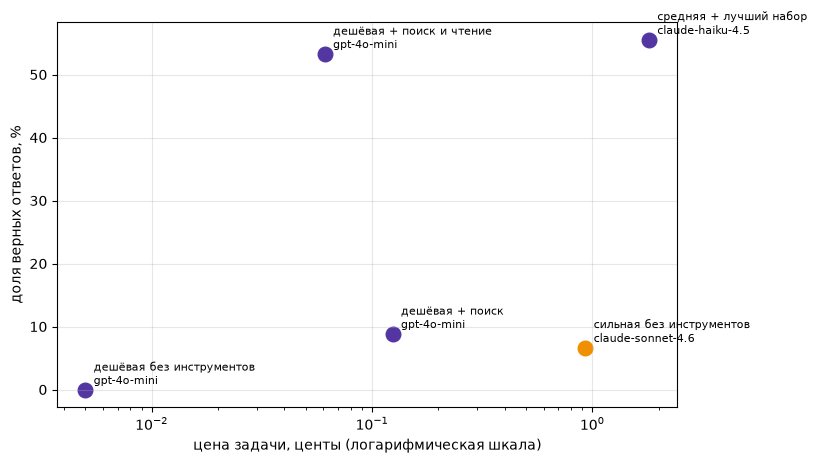

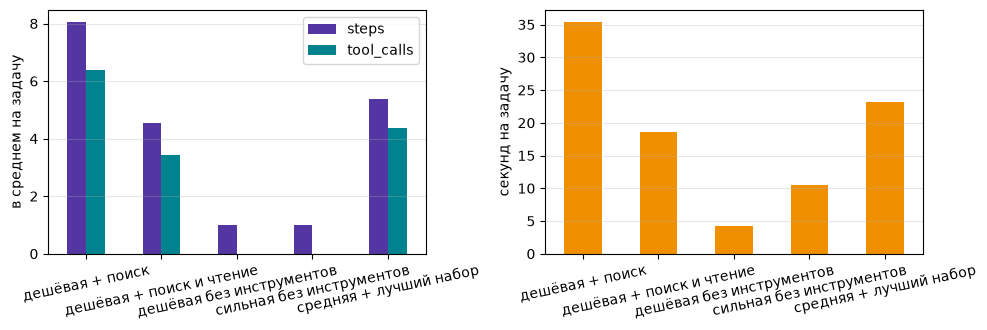

In [35]:
table.to_csv(IMG / "report.csv", index=False)
money_chart(table)
steps_chart(results)

print("=== Итог ===")
print(f"итого потрачено: ${sum(df['cost'].sum() for df in frames):.3f}")